#  Convergence uniforme et limites de l'apprentissage


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import ceil, log

plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def hoeffding(m, eps, K=1):

    return np.minimum(1.0, 2 * K * np.exp(-2 * np.asarray(m) * eps**2))

---
# Partie I — Simulation de la convergence uniforme
## Tâche 1 — Le risque empirique comme variable aléatoire

Pour une hypothèse $h_j$ de risque vrai $p_j$, on simule $E_j\sim\text{Bin}(m,p_j)$ puis $L_S(h_j)=E_j/m$.
On a théoriquement $\mathbb E[L_S(h_j)]=p_j$ (estimateur sans biais) et $\text{Var}(L_S(h_j))=p_j(1-p_j)/m$.
On choisit 4 hypothèses ($p\in\{0{,}1;0{,}3;0{,}5;0{,}8\}$) et 4 tailles ($m\in\{10,50,200,1000\}$).

    p      m  moyenne emp.  |moy - p|  écart-type emp.  sqrt(p(1-p)/m)
 0.10     10        0.1001     0.0001           0.0953          0.0949
 0.10     50        0.0993     0.0007           0.0425          0.0424
 0.10    200        0.0999     0.0001           0.0213          0.0212
 0.10   1000        0.1000     0.0000           0.0094          0.0095
 0.30     10        0.2984     0.0016           0.1452          0.1449
 0.30     50        0.3001     0.0001           0.0646          0.0648
 0.30    200        0.2998     0.0002           0.0322          0.0324
 0.30   1000        0.2999     0.0001           0.0144          0.0145
 0.50     10        0.5005     0.0005           0.1589          0.1581
 0.50     50        0.4999     0.0001           0.0710          0.0707
 0.50    200        0.4999     0.0001           0.0354          0.0354
 0.50   1000        0.5000     0.0000           0.0159          0.0158
 0.80     10        0.8000     0.0000           0.1265          0.1265
 0.80 

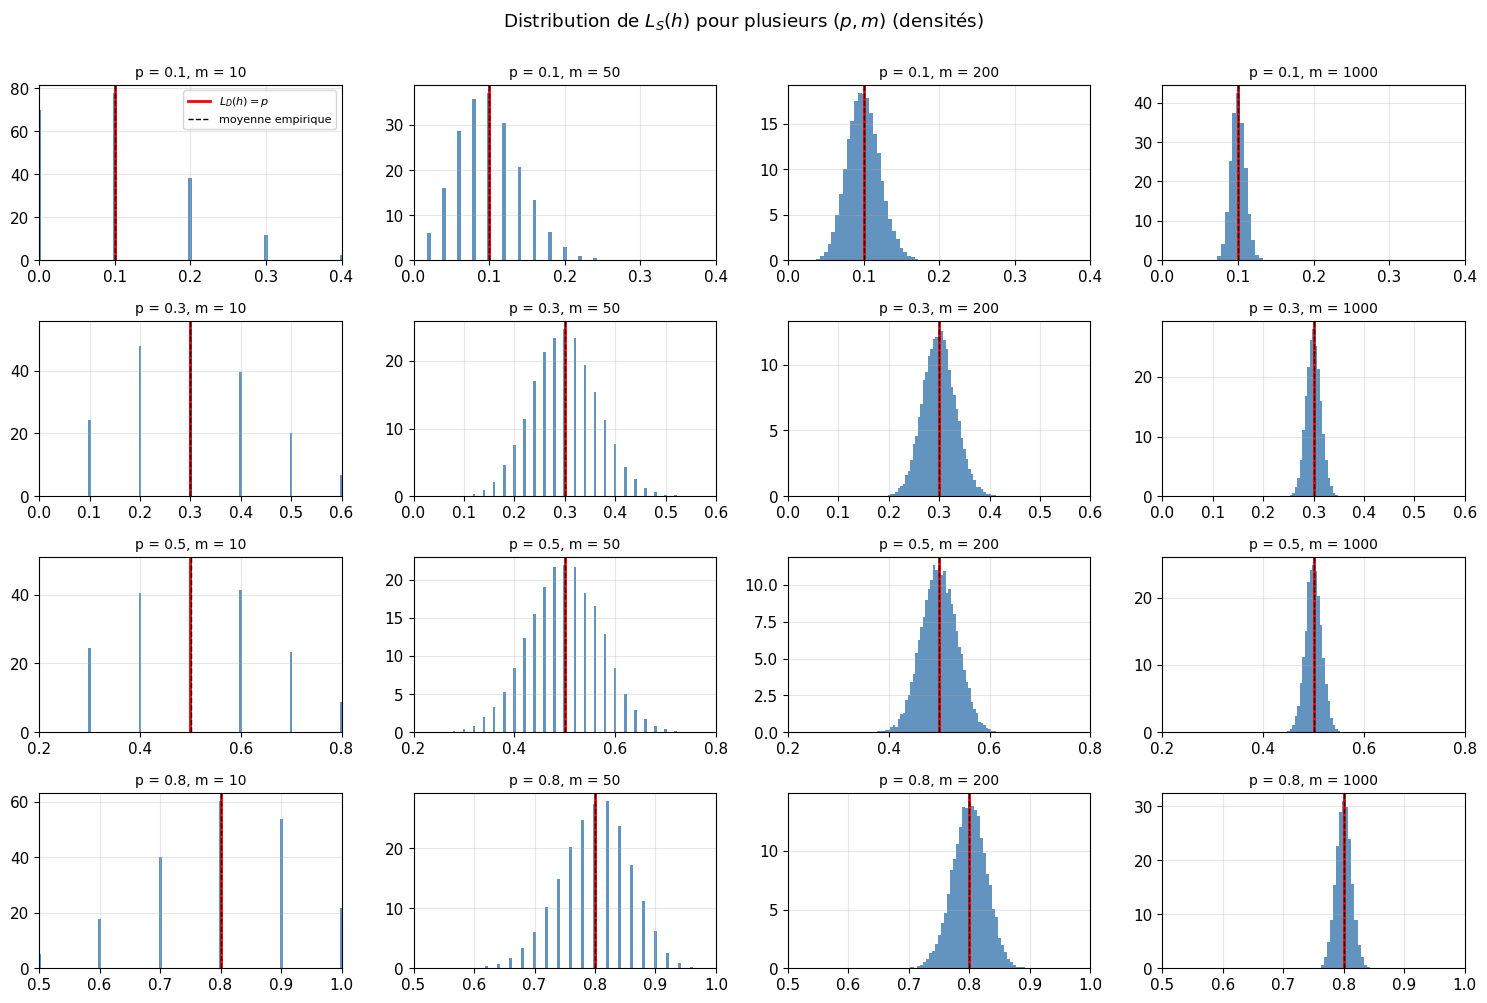

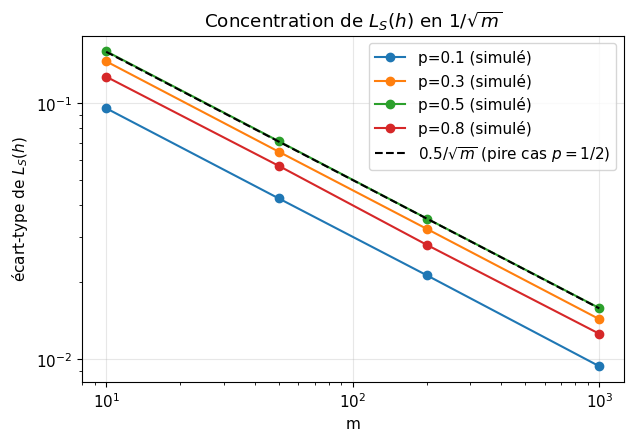

In [2]:
p_list = [0.1, 0.3, 0.5, 0.8]
m_list = [10, 50, 200, 1000]
n_rep = 20_000

fig, axes = plt.subplots(len(p_list), len(m_list), figsize=(15, 10))
std_emp = {}
print(f"{'p':>5} {'m':>6} {'moyenne emp.':>13} {'|moy - p|':>10} {'écart-type emp.':>16} {'sqrt(p(1-p)/m)':>15}")
for i, p in enumerate(p_list):
    for j, m in enumerate(m_list):
        LS = rng.binomial(m, p, size=n_rep) / m
        std_emp[(p, m)] = LS.std()
        ax = axes[i, j]
        bins = np.arange(0, 1.0051, 0.005) - 0.0025
        ax.hist(LS, bins=bins, density=True, color="steelblue", alpha=0.85)
        ax.axvline(p, color="red", lw=2, label=r"$L_D(h)=p$")
        ax.axvline(LS.mean(), color="black", ls="--", lw=1, label="moyenne empirique")
        ax.set_xlim(max(0, p - 0.3), min(1, p + 0.3))
        ax.set_title(f"p = {p}, m = {m}", fontsize=10)
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
        print(f"{p:5.2f} {m:6d} {LS.mean():13.4f} {abs(LS.mean()-p):10.4f} {LS.std():16.4f} {np.sqrt(p*(1-p)/m):15.4f}")
fig.suptitle(r"Distribution de $L_S(h)$ pour plusieurs $(p, m)$ (densités)", y=1.0)
plt.tight_layout(); plt.show()

# Écart-type en fonction de m :
plt.figure()
ms = np.array(m_list)
for p in p_list:
    plt.loglog(ms, [std_emp[(p, m)] for m in ms], "o-", label=f"p={p} (simulé)")
plt.loglog(ms, 0.5 / np.sqrt(ms), "k--", label=r"$0.5/\sqrt{m}$ (pire cas $p=1/2$)")
plt.xlabel("m"); plt.ylabel(r"écart-type de $L_S(h)$"); plt.legend(); plt.title("Concentration de $L_S(h)$ en $1/\\sqrt{m}$")
plt.show()

**Interprétation** : Les résultats affichés confirment la théorie. La moyenne empirique  $L_S(h)$  est extrêmement proche de la vraie valeur $p$ (avec des écarts inférieurs à $2\cdot 10^{-3}$, ce qui correspond bien à l'erreur standard des simulations Monte-Carlo) et  $L_S(h)$ est un estimateur **sans biais** de $L_D(h)$. L'écart-type empirique épouse parfaitement la formule théorique $\sqrt{p(1-p)/m}$.
 Pour les petites valeurs de $m$ ($m=10$), la distribution binomiale est discrète et étalée. Pour $m=1000$, on observe une transition nette vers une courbe en cloche (loi normale), illustrant le Théorème Central Limite (TCL). On note également que la variance estLa variabilité est maximale pour  p=1/2  et plus faible pour  p  proche de  0  ou  1  (variance  p(1−p) )(incertitude maximale d'une variable de Bernoulli).

## Tâche 2 — Écart $|L_S(h)-L_D(h)|$ et borne de Hoeffding

On estime $\Pr[|L_S(h)-L_D(h)|>\varepsilon]$ pour une hypothèse fixée, et on le compare à $2e^{-2m\varepsilon^2}$.
Trois configurations : $(p,\varepsilon)=(0{,}3;0{,}1)$, $(0{,}5;0{,}1)$ (pire cas en variance) et $(0{,}5;0{,}05)$.
(La comparaison $|E-mp|>m\varepsilon$ est faite avec une petite tolérance pour éviter les erreurs d'arrondi flottant.)


p=0.3, eps=0.1: violations de la borne = 0, rapport borne/estimation (médian = 21.0, min = 7.0, max = 109.6)
p=0.5, eps=0.1: violations de la borne = 0, rapport borne/estimation (médian = 9.9, min = 2.7, max = 20.2)
p=0.5, eps=0.05: violations de la borne = 0, rapport borne/estimation (médian = 6.5, min = 4.0, max = 10.2)


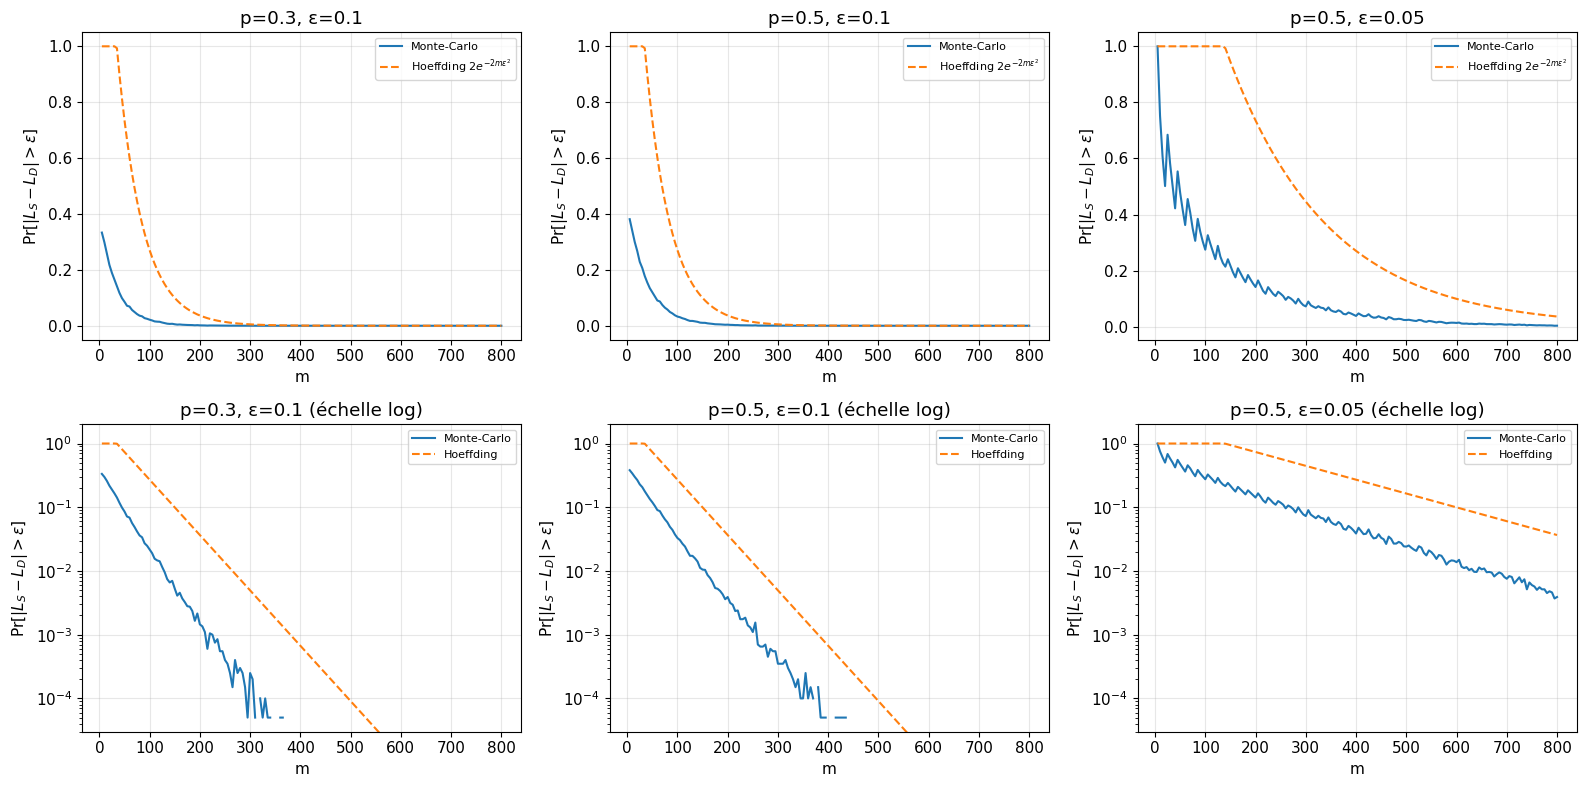

In [3]:
def prob_dev_single(m, p, eps, n_rep):
    E = rng.binomial(m, p, size=n_rep)
    return np.mean(np.abs(E - m * p) > m * eps + 1e-9)

configs = [(0.3, 0.1), (0.5, 0.1), (0.5, 0.05)]
m_grid = np.arange(5, 801, 5)
n_rep = 20_000

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for c, (p, eps) in enumerate(configs):
    emp = np.array([prob_dev_single(m, p, eps, n_rep) for m in m_grid])
    bound = hoeffding(m_grid, eps)
    for r in range(2):
        ax = axes[r, c]
        if r == 0:
            ax.plot(m_grid, emp, label="Monte-Carlo")
            ax.plot(m_grid, bound, "--", label="Hoeffding $2e^{-2m\\varepsilon^2}$")
        else:
            ax.semilogy(m_grid, np.where(emp > 0, emp, np.nan), label="Monte-Carlo")
            ax.semilogy(m_grid, bound, "--", label="Hoeffding")
            ax.set_ylim(3e-5, 2)
        ax.set_title(f"p={p}, ε={eps}" + ("" if r == 0 else " (échelle log)"))
        ax.set_xlabel("m"); ax.set_ylabel(r"$\Pr[|L_S-L_D|>\varepsilon]$")
        ax.legend(fontsize=8)
    mask = (emp > 0) & (bound < 1)
    ratio = bound[mask] / emp[mask]
    print(f"p={p}, eps={eps}: violations de la borne = {np.sum(emp > bound + 3*np.sqrt(bound*(1-bound)/n_rep)):d}, "
          f"rapport borne/estimation (médian = {np.median(ratio):.1f}, min = {ratio.min():.1f}, max = {ratio.max():.1f})")
plt.tight_layout(); plt.show()

**Interprétation.** La probabilité estimée reste **toujours sous** la borne de Hoeffding (0 violation significative dans les trois configurations) et les deux courbes décroissent exponentiellement en $m$.

La borne est cependant **conservative** : le rapport borne/estimation est en médiane d'environ $21$ pour $(p,\varepsilon)=(0{,}3;0{,}1)$, $10$ pour $(0{,}5;0{,}1)$ et $6{,}5$ pour $(0{,}5;0{,}05)$, avec des valeurs extrêmes allant de $\approx 3$ à $\approx 110$. La borne est la plus proche de la réalité dans le pire cas $p=1/2$ (variance maximale), car Hoeffding n'utilise que le fait que $L_S\in[0,1]$ et ignore la variance réelle $p(1-p)/m$ (les inégalités de Bernstein/Chernoff, qui en tiennent compte, seraient plus fines). De plus, elle est triviale ($>1$, donc tronquée à 1) pour les petits $m$. Elle n'est donc **ni exacte ni optimale**, mais elle est **valide** et capture correctement le taux de décroissance exponentiel en $m\varepsilon^2$ (pentes quasi parallèles sur l'échelle log).

## Tâche 3 — De une hypothèse à la convergence uniforme

On prend $|H|=K=50$ hypothèses de risques $p_j$ tirés une fois pour toutes uniformément dans $[0{,}05;0{,}95]$.
Pour chaque échantillon simulé, on tire $E_j\sim\text{Bin}(m,p_j)$ **indépendamment** pour tout $j$ (simplification de l'énoncé), puis on calcule
$\Delta_S=\max_j|L_S(h_j)-p_j|$. On estime $\Pr[\Delta_S>\varepsilon]$ et on la compare à $2|H|e^{-2m\varepsilon^2}$.

ε=0.1: borne non triviale à partir de m≈240 ; l'estimation passe sous 0.5 dès m≈130
ε=0.15: borne non triviale à partir de m≈110 ; l'estimation passe sous 0.5 dès m≈60


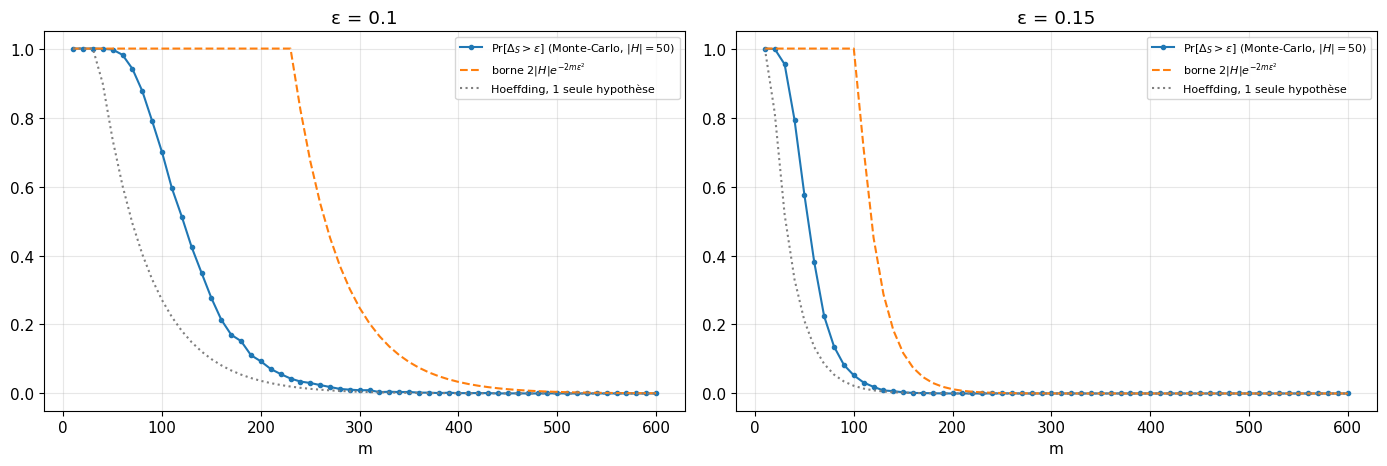

In [4]:
def sample_delta(m, p, n_rep):
    # n_rep réalisations de Delta_S = max_j |L_S(h_j) - p_j|
    E = rng.binomial(m, p, size=(n_rep, len(p)))
    return np.max(np.abs(E - m * p) / m, axis=1)

K3 = 50
p_vec = rng.uniform(0.05, 0.95, size=K3)
m_grid3 = np.arange(10, 601, 10)
n_rep3 = 5000

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, eps in zip(axes, [0.1, 0.15]):
    emp = np.array([np.mean(sample_delta(m, p_vec, n_rep3) > eps + 1e-12) for m in m_grid3])
    ax.plot(m_grid3, emp, "o-", ms=3, label=r"$\Pr[\Delta_S>\varepsilon]$ (Monte-Carlo, $|H|=50$)")
    ax.plot(m_grid3, hoeffding(m_grid3, eps, K3), "--", label=r"borne $2|H|e^{-2m\varepsilon^2}$")
    ax.plot(m_grid3, hoeffding(m_grid3, eps, 1), ":", color="gray", label="Hoeffding, 1 seule hypothèse")
    ax.set_title(f"ε = {eps}"); ax.set_xlabel("m"); ax.legend(fontsize=8)
    # premier m où la borne devient non triviale (<1) et où l'estimation devient < 0.05
    m_b = m_grid3[np.argmax(hoeffding(m_grid3, eps, K3) < 1)]
    m_e = m_grid3[np.argmax(emp < 0.5)]
    print(f"ε={eps}: borne non triviale à partir de m≈{m_b} ; l'estimation passe sous 0.5 dès m≈{m_e}")
plt.tight_layout(); plt.show()

**Interprétation.** Avec $|H|=50$, $\Pr[\Delta_S>\varepsilon]$ reste proche de $1$ pour les petits $m$ : il est très probable qu'**au moins une** des 50 hypothèses ait un risque empirique éloigné de son risque vrai, même si chacune prise isolément est bien estimée. La probabilité de l'événement « il existe $h$ avec un écart $>\varepsilon$ » est bien supérieure à celle d'une seule hypothèse (courbe grise). La borne de l'union $2|H|e^{-2m\varepsilon^2}$ majore bien la simulation, mais elle n'est informative (inférieure à 1) qu'à partir de $m\approx 240$ pour $\varepsilon=0{,}1$ (et $\approx 110$ pour $\varepsilon=0{,}15$), alors que la probabilité simulée passe sous $0{,}5$ dès $m\approx130$ (resp. $\approx 60$) : la borne est donc conservative d'un facteur $\approx 2$ en $m$ dans cette zone. Remarque : comme les erreurs des hypothèses sont simulées de manière indépendante, la borne de l'union est ici *relativement* peu pessimiste ; avec des hypothèses corrélées (cas réel, p. ex. des seuils voisins), $\Delta_S$ serait plus petit et la borne le serait encore davantage.

## Tâche 4 — Effet de la taille de la classe $|H|$

On fixe $\varepsilon=0{,}1$ et $|H|\in\{5,10,50,100,500\}$. Les classes sont **emboîtées** (on garde les $K$ premiers risques d'un même tirage, uniforme dans $[0{,}1;0{,}9]$), de sorte que la comparaison ne dépend pas d'un tirage différent des $p_j$.

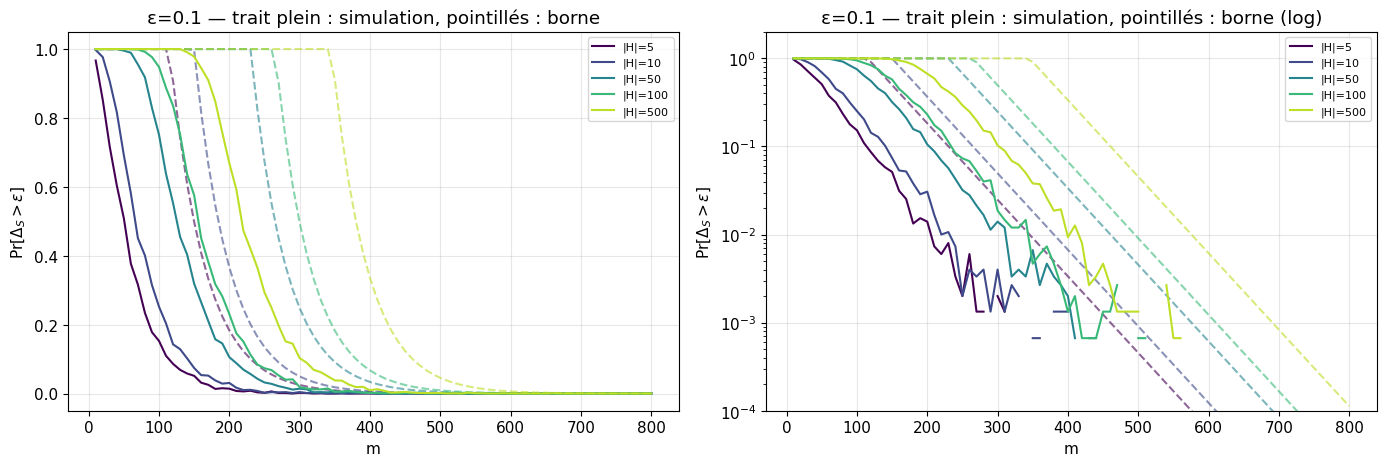

In [5]:
K_list = [5, 10, 50, 100, 500]
eps4 = 0.1
p_master = rng.uniform(0.1, 0.9, size=max(K_list))
m_grid4 = np.arange(10, 801, 10)
n_rep4 = 1500

prob_K = {}
for K in K_list:
    p = p_master[:K]
    prob_K[K] = np.array([np.mean(sample_delta(m, p, n_rep4) > eps4 + 1e-12) for m in m_grid4])

colors = plt.cm.viridis(np.linspace(0, 0.9, len(K_list)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, logy in zip(axes, [False, True]):
    for K, c in zip(K_list, colors):
        if logy:
            ax.semilogy(m_grid4, np.where(prob_K[K] > 0, prob_K[K], np.nan), color=c, label=f"|H|={K}")
        else:
            ax.plot(m_grid4, prob_K[K], color=c, label=f"|H|={K}")
        ax.plot(m_grid4, hoeffding(m_grid4, eps4, K), "--", color=c, alpha=0.6)
    ax.set_xlabel("m"); ax.set_ylabel(r"$\Pr[\Delta_S>\varepsilon]$")
    ax.set_title(f"ε={eps4} — trait plein : simulation, pointillés : borne" + (" (log)" if logy else ""))
    if logy: ax.set_ylim(1e-4, 2)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interprétation.** Plus $|H|$ est grand, plus la courbe $\Pr[\Delta_S>\varepsilon]$ est **décalée vers la droite** : il faut davantage de données pour que la déviation maximale passe sous $\varepsilon$ avec forte probabilité. Intuitivement, chaque hypothèse supplémentaire offre une « chance » de plus d'avoir un risque empirique trompeur ; à $m$ fixé, la probabilité qu'au moins une le soit croît avec $|H|$ (la borne de l'union la majore par $2|H|e^{-2m\varepsilon^2}$). Ce décalage n'est toutefois **pas proportionnel** à $|H|$ : multiplier la taille de la classe par 100 (de 5 à 500) ne décale la courbe que d'environ $200$ points en $m$ (voir Tâche 5). Cela correspond à la dépendance en $\log|H|$ des bornes : résoudre $2|H|e^{-2m\varepsilon^2}\le\delta$ donne $m\ge\log(2|H|/\delta)/(2\varepsilon^2)$, de sorte que $|H|$ n'intervient que par son logarithme, c.-à-d. le nombre de bits nécessaires pour décrire une hypothèse. Une grande classe exige donc *un peu* plus de données, pas « beaucoup plus ».

## Tâche 5 — Complexité d'échantillonnage expérimentale

Avec $\varepsilon=0{,}1$ et $\delta\in\{0{,}1;0{,}05\}$, on cherche le plus petit $m$ de la grille (pas de 10) tel que $\Pr[\Delta_S>\varepsilon]\le\delta$ et on le compare à
$$m_{\text{th}}=\left\lceil\frac{\log(2|H|/\delta)}{2\varepsilon^2}\right\rceil .$$


--- ε = 0.1, δ = 0.1 ---
  |H|  m expérimental  m théorique  rapport théo/exp
    5             120          231              1.93
   10             150          265              1.77
   50             210          346              1.65
  100             240          381              1.59
  500             310          461              1.49

--- ε = 0.1, δ = 0.05 ---
  |H|  m expérimental  m théorique  rapport théo/exp
    5             160          265              1.66
   10             180          300              1.67
   50             240          381              1.59
  100             280          415              1.48
  500             340          496              1.46

Pente de m en fonction de log|H| : expérimentale ≈ 39.9, théorique = 1/(2ε²) = 50.0


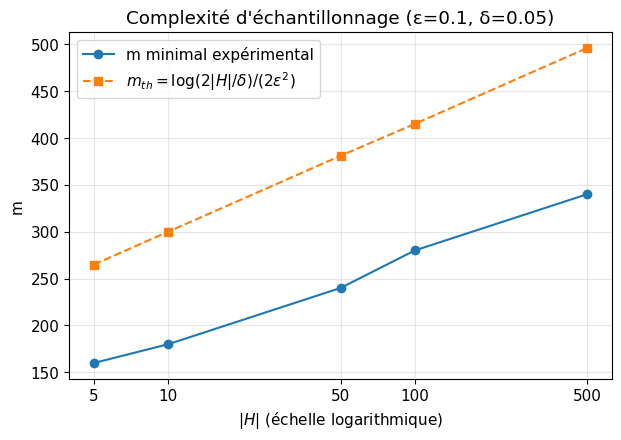

In [6]:
def first_m_below(m_grid, prob, delta):
    ok = np.where(prob <= delta)[0]
    return int(m_grid[ok[0]]) if len(ok) else None

def m_theory(K, eps, delta):
    return ceil(log(2 * K / delta) / (2 * eps**2))

results = {}
for delta in [0.1, 0.05]:
    print(f"\n--- ε = {eps4}, δ = {delta} ---")
    print(f"{'|H|':>5} {'m expérimental':>15} {'m théorique':>12} {'rapport théo/exp':>17}")
    for K in K_list:
        m_e = first_m_below(m_grid4, prob_K[K], delta)
        m_t = m_theory(K, eps4, delta)
        results[(K, delta)] = (m_e, m_t)
        print(f"{K:5d} {m_e:15d} {m_t:12d} {m_t/m_e:17.2f}")

# m (expérimental / théorique) en fonction de log|H|
delta = 0.05
logK = np.log(K_list)
m_exp = np.array([results[(K, delta)][0] for K in K_list])
m_the = np.array([results[(K, delta)][1] for K in K_list])
slope_e, icpt_e = np.polyfit(logK, m_exp, 1)
slope_t, icpt_t = np.polyfit(logK, m_the, 1)
print(f"\nPente de m en fonction de log|H| : expérimentale ≈ {slope_e:.1f}, théorique = 1/(2ε²) = {1/(2*eps4**2):.1f}")

plt.figure()
plt.plot(logK, m_exp, "o-", label="m minimal expérimental")
plt.plot(logK, m_the, "s--", label=r"$m_{th}=\log(2|H|/\delta)/(2\varepsilon^2)$")
plt.xticks(logK, [str(K) for K in K_list])
plt.xlabel(r"$|H|$ (échelle logarithmique)"); plt.ylabel("m")
plt.title(f"Complexité d'échantillonnage (ε={eps4}, δ={delta})"); plt.legend(); plt.show()

**Interprétation.** Pour $\varepsilon=0{,}1$ et $\delta=0{,}05$, le $m$ minimal expérimental va de $160$ ($|H|=5$) à $340$ ($|H|=500$), contre $265$ à $496$ pour la formule théorique : la borne théorique est **suffisante** (aucun cas où l'expérience demande plus) mais surestime d'un facteur $\approx 1{,}5$ à $1{,}9$ (rapports $1{,}66$ à $1{,}46$ ; $1{,}93$ à $1{,}49$ pour $\delta=0{,}1$). Le rapport diminue quand $|H|$ augmente, car l'union bound devient relativement plus serrée quand le nombre d'événements à contrôler est grand. La croissance en $\log|H|$ est bien observée (points alignés sur l'échelle log) : pente expérimentale $\approx 40$ contre $1/(2\varepsilon^2)=50$ théorique. Cette borne est un **garantie suffisante valable pour toute distribution des risques $p_j$** et pour toute classe (même avec hypothèses dépendantes) : elle repose sur Hoeffding (qui ignore la variance) et sur l'union bound (qui suppose le pire cas où les événements « mauvais » sont disjoints). Ici les risques vrais sont diffus dans $[0{,}1;0{,}9]$ et seul un sous-ensemble d'hypothèses est vraiment critique ; le minimum exact est donc inférieur au $m$ garanti. Précision : l'expérience a une résolution de $10$ en $m$ et une incertitude Monte-Carlo (1500 répétitions) ; l'ordre de grandeur et la conclusion sont néanmoins robustes.

---
# Partie II — Simulation du No-Free-Lunch

Domaine $\mathcal X=\{1,\dots,N\}$, loi uniforme. À chaque répétition : une cible $f$ avec $f(x)\sim\text{Bernoulli}(1/2)$ i.i.d., puis un échantillon de $m$ points i.i.d. uniformes (les étiquettes sont celles de $f$, sans bruit). Le **simulateur** ci-dessous est vectorisé sur les répétitions et gère les trois règles pour les points non vus (`zero`, `one`, `random`) ; par défaut, l'apprenant de l'énoncé prédit 0 sur les points non vus.

In [ ]:
def simulate_task(N, m, n_rep, rule="zero", f=None):
    # n_rep tâches d'apprentissage indépendantes. Retourne (fraction de points non vus, risque réel L_D(A(S))).
    # rule : prédiction sur un point non vu ('zero', 'one' ou 'random').
    # f    : cible fixée (vecteur de taille N) ; si None, cible aléatoire à chaque répétition.
    F = rng.integers(0, 2, size=(n_rep, N)) if f is None else np.tile(np.asarray(f), (n_rep, 1))
    idx = rng.integers(0, N, size=(n_rep, m))              # points échantillonnés
    seen = np.zeros((n_rep, N), dtype=bool)
    seen[np.arange(n_rep)[:, None], idx] = True            # points vus au moins une fois
    if rule == "zero":     fill = np.zeros((n_rep, N), dtype=int)
    elif rule == "one":    fill = np.ones((n_rep, N), dtype=int)
    elif rule == "random": fill = rng.integers(0, 2, size=(n_rep, N))
    else: raise ValueError(rule)
    pred = np.where(seen, F, fill)                         # mémorisation si vu, règle sinon
    risk = (pred != F).mean(axis=1)                        # L_D(A(S)) sur tout le domaine
    return 1 - seen.mean(axis=1), risk

## Tâche 6 — Points vus et non vus

Pour un point fixé $x$, chaque tirage ne l'atteint pas avec probabilité $1-\frac1N$ ; les $m$ tirages étant indépendants,
$\Pr[x\text{ non vu}]=(1-\frac1N)^m$. La fraction de points non vus est $U=\frac1N\sum_{x}\mathbf 1[x\text{ non vu}]$, donc par **linéarité de l'espérance** (aucune indépendance entre les points n'est nécessaire)
$$\mathbb E[U]=\frac1N\sum_x\Pr[x\text{ non vu}]=\Big(1-\frac1N\Big)^m\approx e^{-m/N}.$$

N=  20 : écart maximal |simulation - théorie| = 0.0025
N= 100 : écart maximal |simulation - théorie| = 0.0017
N= 500 : écart maximal |simulation - théorie| = 0.0008


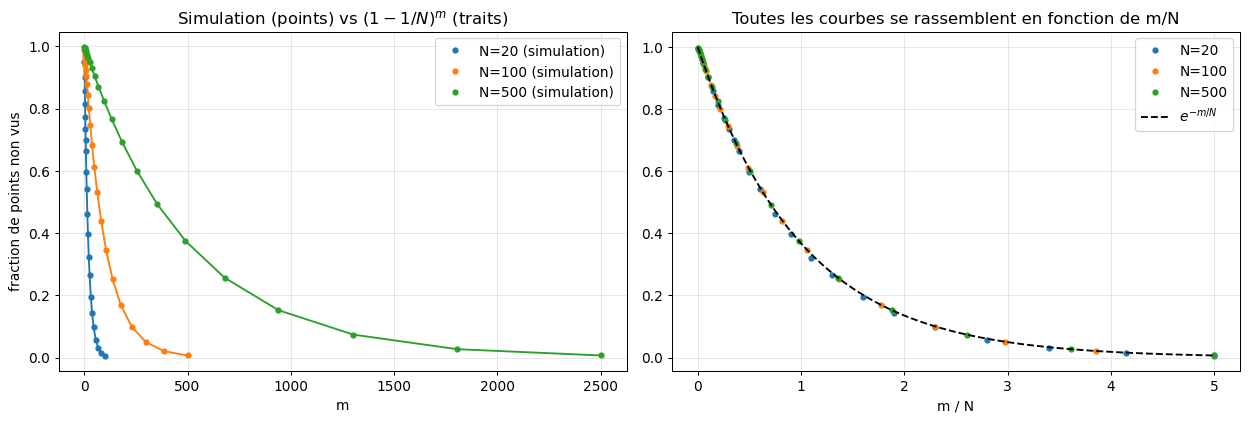

In [ ]:
N_list6 = [20, 100, 500]
n_rep6 = 1000
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for N in N_list6:
    m_grid = np.unique(np.round(np.logspace(0, np.log10(5 * N), 25)).astype(int))
    emp = np.array([simulate_task(N, m, n_rep6)[0].mean() for m in m_grid])
    th = (1 - 1 / N) ** m_grid
    l, = axes[0].plot(m_grid, emp, "o", ms=4, label=f"N={N} (simulation)")
    axes[0].plot(m_grid, th, "-", color=l.get_color())
    axes[1].plot(m_grid / N, emp, "o", ms=4, color=l.get_color(), label=f"N={N}")
    print(f"N={N:4d} : écart maximal |simulation - théorie| = {np.max(np.abs(emp - th)):.4f}")
axes[0].set_xlabel("m"); axes[0].set_ylabel("fraction de points non vus"); axes[0].set_title("Simulation (points) vs $(1-1/N)^m$ (traits)"); axes[0].legend()
xs = np.linspace(0, 5, 200)
axes[1].plot(xs, np.exp(-xs), "k--", label=r"$e^{-m/N}$")
axes[1].set_xlabel("m / N"); axes[1].set_title("Toutes les courbes se rassemblent en fonction de m/N"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interprétation.** La fraction simulée de points non vus suit la formule $(1-1/N)^m$ avec un écart maximal $\le 2{,}5\cdot10^{-3}$, compatible avec le bruit Monte-Carlo. En fonction de $m/N$, les trois courbes ($N=20,100,500$) se confondent sur $e^{-m/N}$ : ce qui compte est le **rapport entre taille de l'échantillon et taille du domaine**. Pour voir la quasi-totalité du domaine il faut $m\gg N$ (par ex. il reste encore $\approx 37\,\%$ de points non vus à $m=N$ et $\approx 5\,\%$ à $m=3N$).

## Tâche 7 — Erreur sur les points non vus

**Dérivation.** Soit $A$ l'algorithme de mémorisation (prédit 0 hors échantillon).
- Si $x$ est vu, $A(S)(x)=f(x)$ : aucune erreur (échantillon sans bruit).
- Si $x$ est non vu, $A(S)(x)=0$. L'événement « $x$ non vu » ne dépend que des **positions** tirées, alors que $f(x)\sim\text{Bernoulli}(1/2)$ est indépendant de ces positions. Donc $\Pr[A(S)(x)\neq f(x)\mid x\text{ non vu}]=\Pr[f(x)=1]=\frac{1}{2}$.

D'où
$$\mathbb E[L_D(A(S))]=\frac1N\sum_x\Pr[x\text{ non vu}]\cdot\frac{1}{2}=\frac{1}{2}\Big(1-\frac1N\Big)^m .$$

N=20: écart max = 0.0024 ; 96 % des points dans l'IC à 95 % de la théorie
N=100: écart max = 0.0009 ; 100 % des points dans l'IC à 95 % de la théorie


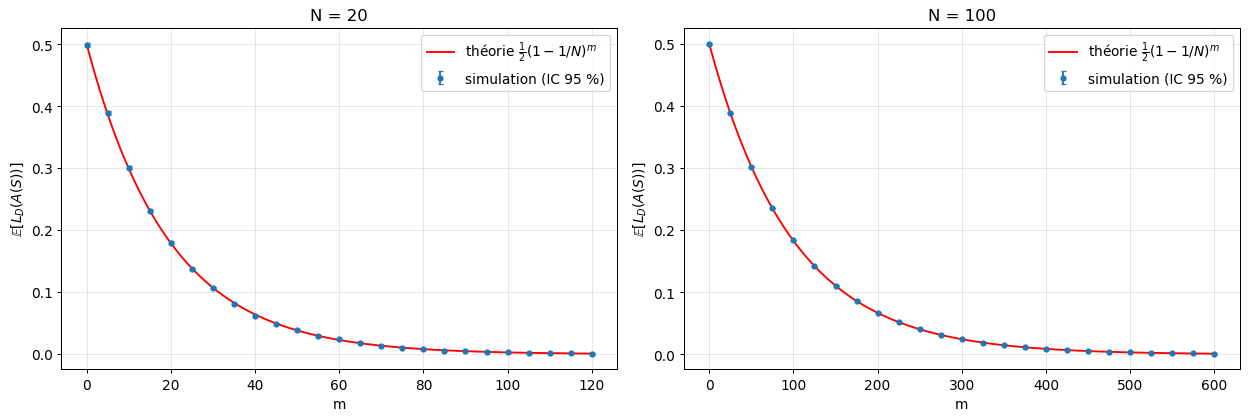

In [ ]:
N_list7 = [20, 100]
n_rep7 = 5000
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, N in zip(axes, N_list7):
    m_grid = np.unique(np.round(np.linspace(0, 6 * N, 25)).astype(int))
    mean_r, se_r = [], []
    for m in m_grid:
        r = simulate_task(N, m, n_rep7, rule="zero")[1]
        mean_r.append(r.mean()); se_r.append(r.std(ddof=1) / np.sqrt(n_rep7))
    mean_r, se_r = np.array(mean_r), np.array(se_r)
    th = 0.5 * (1 - 1 / N) ** m_grid
    ax.errorbar(m_grid, mean_r, yerr=1.96 * se_r, fmt="o", ms=4, capsize=2, label="simulation (IC 95 %)")
    mm = np.arange(0, 6 * N + 1)
    ax.plot(mm, 0.5 * (1 - 1 / N) ** mm, "r-", label=r"théorie $\frac{1}{2}(1-1/N)^m$")
    ax.set_title(f"N = {N}"); ax.set_xlabel("m"); ax.set_ylabel(r"$\mathbb{E}[L_D(A(S))]$"); ax.legend()
    inside = np.mean(np.abs(mean_r - th) <= 1.96 * se_r + 1e-12)
    print(f"N={N}: écart max = {np.max(np.abs(mean_r - th)):.4f} ; {100*inside:.0f} % des points dans l'IC à 95 % de la théorie")
plt.tight_layout(); plt.show()

**Interprétation.** Les risques moyens simulés sont en accord avec $\frac{1}{2}(1-1/N)^m$ : écart maximal de l'ordre de $10^{-3}$ et $96$–$100\,\%$ des points dans l'intervalle de confiance à $95\,\%$ de la théorie (le taux attendu est $\approx 95\,\%$). Avec $N=100$ et $m=100$, le risque reste de $\approx 0{,}18$ : mémoriser 100 exemples n'apprend presque rien sur les $\approx 37$ points non vus, dont la moitié est mal prédite. À $m=0$ le risque vaut $1/2$ (devinette) et il ne décroît que par l'élimination progressive des points non vus ; la décroissance est exponentielle en $m/N$ : le learner ne **généralise pas**, il ne fait que **mémoriser**.

## Tâche 8 — Changer la prédiction sur les points non vus

On compare les règles `zero`, `one`, `random` (cibles tirées uniformément). On illustre ensuite le point clé : **pour une cible fixée**, une règle peut être parfaite ou catastrophique, mais **en moyenne sur toutes les cibles** elles sont équivalentes.

Écart maximal entre règles (sur la grille de m) : 0.0010 (erreur standard ≈ 0.0035)

Risque moyen pour m=20, N=50
                   cible     zero      one   random
                   f ≡ 0    0.000    0.668    0.334
                   f ≡ 1    0.667    0.000    0.334
   f aléatoire (moyenne)    0.334    0.333    0.334
Référence théorique : (1-1/N)^m = 0.668,  moitié = 0.334


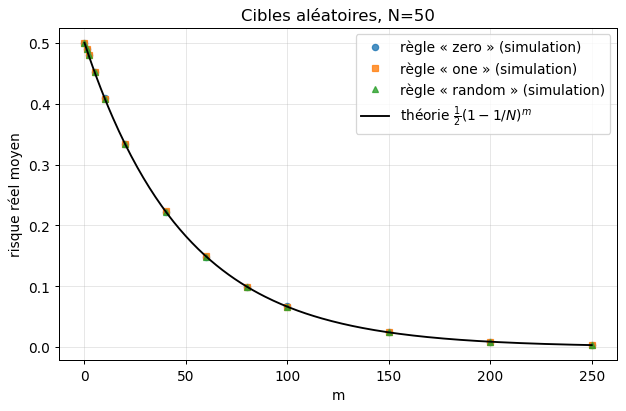

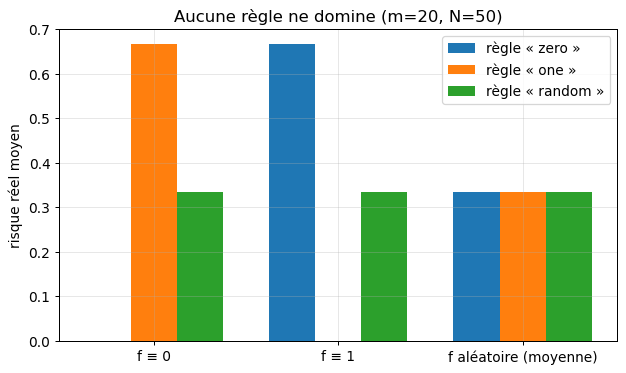

In [ ]:
N8 = 50
m_grid8 = np.array([0, 1, 2, 5, 10, 20, 40, 60, 80, 100, 150, 200, 250])
n_rep8 = 20_000
rules = ["zero", "one", "random"]
mean8 = {}
for rule in rules:
    mean8[rule] = np.array([simulate_task(N8, m, n_rep8, rule=rule)[1].mean() for m in m_grid8])

plt.figure(figsize=(8, 4.8))
for rule, mk in zip(rules, ["o", "s", "^"]):
    plt.plot(m_grid8, mean8[rule], mk, ms=5, alpha=0.8, label=f"règle « {rule} » (simulation)")
mm = np.arange(0, 251)
plt.plot(mm, 0.5 * (1 - 1 / N8) ** mm, "k-", label=r"théorie $\frac{1}{2}(1-1/N)^m$")
plt.xlabel("m"); plt.ylabel("risque réel moyen"); plt.title(f"Cibles aléatoires, N={N8}"); plt.legend(); plt.show()

se = np.sqrt(0.25 / n_rep8)   # ordre de grandeur de l'erreur standard
print("Écart maximal entre règles (sur la grille de m) :",
      f"{max(np.max(np.abs(mean8[a]-mean8[b])) for a in rules for b in rules):.4f}", f"(erreur standard ≈ {se:.4f})")

# Cibles FIXÉES vs cibles aléatoires, m = 20
m_fix = 20
targets = {"f ≡ 0": np.zeros(N8, dtype=int), "f ≡ 1": np.ones(N8, dtype=int), "f aléatoire (moyenne)": None}
risk_table = {t: [simulate_task(N8, m_fix, 20_000, rule=r, f=f)[1].mean() for r in rules] for t, f in targets.items()}
print(f"\nRisque moyen pour m={m_fix}, N={N8}")
print(f"{'cible':>24} " + " ".join(f"{r:>8}" for r in rules))
for t, v in risk_table.items():
    print(f"{t:>24} " + " ".join(f"{x:8.3f}" for x in v))
print(f"Référence théorique : (1-1/N)^m = {(1-1/N8)**m_fix:.3f},  moitié = {0.5*(1-1/N8)**m_fix:.3f}")

x = np.arange(len(targets)); w = 0.25
plt.figure(figsize=(8, 4.5))
for k, r in enumerate(rules):
    plt.bar(x + (k - 1) * w, [risk_table[t][k] for t in targets], w, label=f"règle « {r} »")
plt.xticks(x, list(targets)); plt.ylabel("risque réel moyen"); plt.title(f"Aucune règle ne domine (m={m_fix}, N={N8})"); plt.legend(); plt.show()

**Interprétation.** Les trois règles (`zero`, `one`, `random`) ont des risques moyens indistinguables (écart maximal entre règles $\approx 10^{-3}$, inférieur à l'erreur standard $\approx 3{,}5\cdot10^{-3}$) et tous égaux à $\frac{1}{2}(1-1/N)^m$ : sur des cibles uniformément aléatoires, **aucune stratégie ne surpasse les autres**. Le second tableau montre pourquoi : pour la cible fixée $f\equiv 0$, la règle « zéro » est parfaite (risque $0$) mais la règle « un » est mauvaise ($\approx 0{,}67$) ; pour $f\equiv 1$ c'est l'inverse ; la règle aléatoire donne $0{,}33$ dans les deux cas. En moyenne sur les cibles, les trois valent $0{,}334$. Un algorithme n'est « bon » que sur les cibles pour lesquelles ses hypothèses implicites sont correctes. C'est exactement le **No-Free-Lunch** : moyenné uniformément sur toutes les fonctions cibles, aucun apprenant n'est meilleur qu'un autre sur les points hors échantillon, car les étiquettes non vues sont indépendantes des étiquettes vues et donc inprédictibles ; tout gain sur certaines cibles est compensé par une perte sur d'autres.

---
# Partie III — Introduction de connaissances a priori

Cibles de type seuil $f_\theta(x)=\mathbf 1[x>\theta]$, $\theta\in\{1,\dots,N-1\}$, et classe $H=\{h_t:t\in\{1,\dots,N-1\}\}$, $h_t(x)=\mathbf 1[x>t]$.

**ERM sur les seuils.** Le problème est réalisable ($f_\theta\in H$), donc le minimum de l'erreur d'entraînement est 0. Les seuils $t$ cohérents avec l'échantillon vérifient :
- pour tout exemple d'étiquette 0 : $x\le t$, donc $t\ge a:=\max\{x_i:y_i=0\}$ (ou $1$ s'il n'y en a pas) ;
- pour tout exemple d'étiquette 1 : $x>t$, donc $t\le b-1$ avec $b:=\min\{x_i:y_i=1\}$ (ou $N$ s'il n'y en a pas).

L'ensemble des minimiseurs est donc l'intervalle d'entiers $[a,\,b-1]$ ; il est non vide car $a\le\theta\le b-1$. L'ERM doit choisir un élément de cet intervalle (règle de départage : `min`, `max`, `mid` ou `random`). Le risque réel sur le domaine est le nombre de points où $h_t$ et $f_\theta$ diffèrent, c.-à-d. $|t-\theta|$ points : $L_D(h_t)=|t-\theta|/N$.

Avant les expériences, on **vérifie** cette implémentation vectorisée contre une ERM par force brute (énumération de tous les $t$ et calcul explicite des risques sur le domaine).

In [ ]:
def erm_threshold(x, y, N, tie="random"):
    # ERM sur les seuils, vectorisé. x, y : tableaux (n_rep, m) ; y booléen.
    # Retourne (t choisi, borne basse a, borne haute b-1) de l'intervalle des seuils cohérents.
    a = np.where(~y, x, 1).max(axis=1)        # t >= a
    b = np.where(y, x, N).min(axis=1)         # t <= b-1
    if tie == "min":      t = a
    elif tie == "max":    t = b - 1
    elif tie == "mid":    t = (a + b - 1) // 2
    elif tie == "random": t = a + np.floor(rng.random(len(a)) * (b - a)).astype(int)
    else: raise ValueError(tie)
    return t, a, b - 1

def simulate_threshold(N, m, n_rep, tie="random"):
    # Risques réels L_D(h_S) de n_rep tâches 'cible seuil + ERM sur seuils'.
    theta = rng.integers(1, N, size=n_rep)                    # θ ∈ {1,...,N-1}
    x = rng.integers(1, N + 1, size=(n_rep, m))               # échantillon dans {1,...,N}
    y = x > theta[:, None]
    t, _, _ = erm_threshold(x, y, N, tie)
    return np.abs(t - theta) / N

def check_erm(N=12, m=5, trials=300):
    # Vérification contre la force brute
    for _ in range(trials):
        theta = rng.integers(1, N); x = rng.integers(1, N + 1, size=m); y = x > theta
        ts = np.arange(1, N)
        train_err = np.array([np.mean((x > t) != y) for t in ts])
        erm_set = ts[train_err == train_err.min()]
        _, lo, hi = erm_threshold(x[None, :], y[None, :], N)
        assert train_err.min() == 0 and erm_set.min() == lo[0] and erm_set.max() == hi[0]
        dom = np.arange(1, N + 1)
        for t in erm_set:
            assert np.isclose(np.mean((dom > t) != (dom > theta)), abs(t - theta) / N)
    print(f"Vérification ERM / risque réel : OK ({trials} tâches aléatoires, N={N}, m={m})")
check_erm()

Vérification ERM / risque réel : OK (300 tâches aléatoires, N=12, m=5)


## Tâche 9 — Apprendre avec un biais inductif adapté

On estime $\mathbb E[L_D(h_S)]$ pour $N=100$ et plusieurs $m$ (5000 répétitions). On compare :
- les 4 règles de départage de l'ERM ;
- le risque des cibles aléatoires de la Partie II, $\frac{1}{2}(1-1/N)^m$ ;
- la borne réalisable $\log(|H|/\delta)/m$ (avec $\delta=0{,}05$) comparée au quantile à 95 % du risque de l'ERM.

N = 100
    m   ERM min   ERM max   ERM mid  ERM rand  quantile95  borne réal.  cible aléa.
    1    0.3235    0.3234    0.1675    0.2212      0.6000       1.0000       0.4950
    2    0.2532    0.2447    0.1262    0.1649      0.4700       1.0000       0.4900
    3    0.1925    0.1980    0.0998    0.1347      0.3900       1.0000       0.4851
    5    0.1390    0.1389    0.0724    0.0949      0.2900       1.0000       0.4755
    8    0.0961    0.0943    0.0494    0.0656      0.2000       0.9489       0.4614
   10    0.0793    0.0781    0.0416    0.0552      0.1700       0.7591       0.4522
   15    0.0550    0.0548    0.0295    0.0382      0.1200       0.5061       0.4300
   20    0.0403    0.0400    0.0218    0.0285      0.0900       0.3795       0.4090
   30    0.0264    0.0263    0.0152    0.0198      0.0700       0.2530       0.3699
   50    0.0141    0.0146    0.0093    0.0115      0.0400       0.1518       0.3025
   75    0.0087    0.0086    0.0058    0.0073      0.0300       0.10

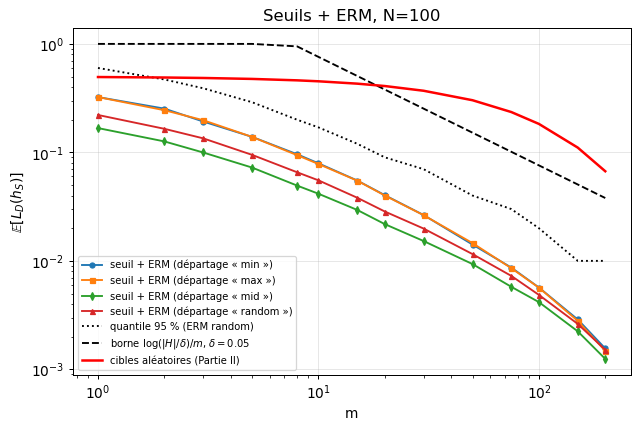

In [ ]:
N9 = 100
m_list9 = np.array([1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200])
n_rep9 = 5000
ties = ["min", "max", "mid", "random"]

risk9 = {tie: [simulate_threshold(N9, m, n_rep9, tie) for m in m_list9] for tie in ties}
mean9 = {tie: np.array([r.mean() for r in risk9[tie]]) for tie in ties}
q95 = np.array([np.quantile(r, 0.95) for r in risk9["random"]])
rand_th = 0.5 * (1 - 1 / N9) ** m_list9
bound_realizable = np.minimum(1, np.log((N9 - 1) / 0.05) / m_list9)

print(f"N = {N9}")
print(f"{'m':>5} {'ERM min':>9} {'ERM max':>9} {'ERM mid':>9} {'ERM rand':>9} {'quantile95':>11} {'borne réal.':>12} {'cible aléa.':>12}")
for k, m in enumerate(m_list9):
    print(f"{m:5d} {mean9['min'][k]:9.4f} {mean9['max'][k]:9.4f} {mean9['mid'][k]:9.4f} {mean9['random'][k]:9.4f} "
          f"{q95[k]:11.4f} {bound_realizable[k]:12.4f} {rand_th[k]:12.4f}")

plt.figure(figsize=(8, 5))
for tie, mk in zip(ties, ["o", "s", "d", "^"]):
    plt.loglog(m_list9, mean9[tie], mk + "-", ms=4, label=f"seuil + ERM (départage « {tie} »)")
plt.loglog(m_list9, q95, "k:", label="quantile 95 % (ERM random)")
plt.loglog(m_list9, bound_realizable, "k--", label=r"borne $\log(|H|/\delta)/m$, $\delta=0.05$")
plt.loglog(m_list9, rand_th, "r-", lw=2, label="cibles aléatoires (Partie II)")
plt.xlabel("m"); plt.ylabel(r"$\mathbb{E}[L_D(h_S)]$"); plt.title(f"Seuils + ERM, N={N9}"); plt.legend(fontsize=8); plt.show()

**Interprétation.** Avec le biais inductif « seuils », le risque décroît **beaucoup plus vite** qu'avec des cibles aléatoires : pour $N=100$, le risque moyen de l'ERM vaut $\approx 0{,}055$ (départage aléatoire) pour $m=10$ contre $0{,}452$ pour les cibles aléatoires ; il est inférieur à $0{,}006$ pour $m=100$ (contre $0{,}18$). Le risque est approximativement en $1/m$ (pente $-1$ en log-log) : le learner exploite les exemples pour **localiser le seuil**, et le risque est proportionnel à la taille de l'intervalle $[a,b-1]$ d'incertitude (les $\approx N/m$ points entre deux exemples consécutifs). Le choix de départage parmi les ERM (tous consistants) change le risque d'un facteur $\le 2$ sans changer l'ordre de grandeur : « mid » (milieu de l'intervalle) est le meilleur car il minimise le pire cas ($\approx 0{,}042$ à $m=10$ contre $\approx 0{,}079$ pour « min »/« max »). La borne réalisable $\log(|H|/\delta)/m$ majore bien le quantile à 95 % observé (par ex. $0{,}76$ vs $0{,}17$ à $m=10$) mais est conservative d'un facteur $\approx 4$ à $5$.

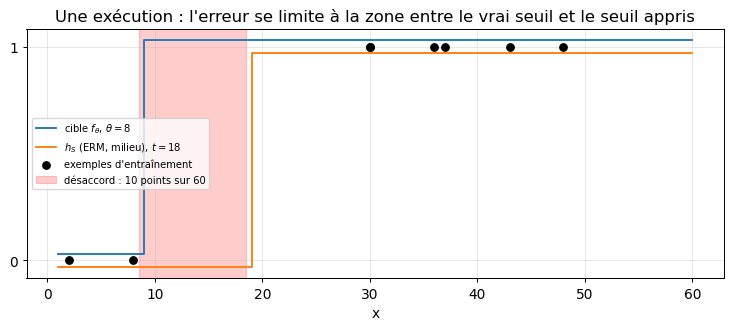

In [ ]:
# Illustration d'une exécution : N=60, m=8
rg = np.random.default_rng(11)
N_i, m_i = 60, 8
theta_i = int(rg.integers(1, N_i))
xs = rg.integers(1, N_i + 1, size=m_i); ys = xs > theta_i
a_i = max([x for x, y in zip(xs, ys) if not y] + [1]); b_i = min([x for x, y in zip(xs, ys) if y] + [N_i])
t_i = (a_i + b_i - 1) // 2
dom = np.arange(1, N_i + 1)
plt.figure(figsize=(10, 3.6))
plt.step(dom, (dom > theta_i).astype(int) + 0.03, where="post", label=fr"cible $f_\theta$, $\theta={theta_i}$")
plt.step(dom, (dom > t_i).astype(int) - 0.03, where="post", label=fr"$h_S$ (ERM, milieu), $t={t_i}$")
plt.scatter(xs, ys.astype(int), c="k", zorder=5, label="exemples d'entraînement")
plt.axvspan(min(t_i, theta_i) + 0.5, max(t_i, theta_i) + 0.5, color="red", alpha=0.2, label=f"désaccord : {abs(t_i-theta_i)} points sur {N_i}")
plt.yticks([0, 1]); plt.xlabel("x"); plt.legend(fontsize=8, loc="center left"); plt.title("Une exécution : l'erreur se limite à la zone entre le vrai seuil et le seuil appris"); plt.show()

## Tâche 10 — Cibles aléatoires vs cibles structurées

On trace le risque réel en fonction de $m$ pour (a) cibles aléatoires (règle « zéro », points simulés + formule) et (b) cibles seuil + ERM, pour $N=100$ et $N=1000$ (échelle logarithmique en $m$ et en risque).

N=  100: m nécessaire pour un risque moyen <= 0.05 : cibles aléatoires ≈ 230 (théorie), seuils ≈ 13 (grille)
        à m=10 : aléatoire = 0.452, seuil = 0.057
N= 1000: m nécessaire pour un risque moyen <= 0.05 : cibles aléatoires ≈ 2302 (théorie), seuils ≈ 12 (grille)
        à m=10 : aléatoire = 0.495, seuil = 0.054


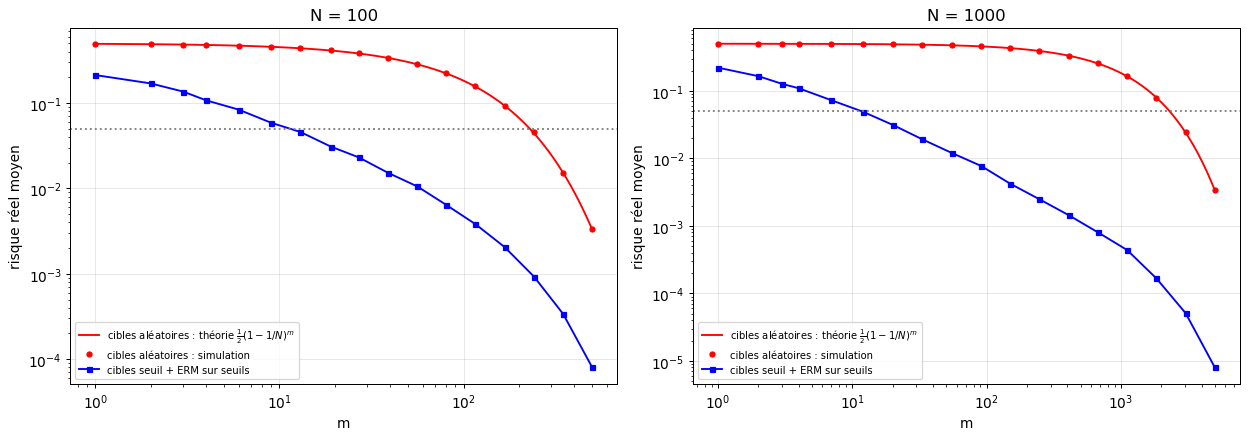

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
target_risk = 0.05
for ax, N in zip(axes, [100, 1000]):
    m_grid = np.unique(np.round(np.logspace(0, np.log10(5 * N), 18)).astype(int))
    r_rand = np.array([simulate_task(N, m, 300, rule="zero")[1].mean() for m in m_grid])
    r_thr = np.array([simulate_threshold(N, m, 1000, "random").mean() for m in m_grid])
    mm = np.unique(np.round(np.logspace(0, np.log10(5 * N), 200)).astype(int))
    ax.loglog(mm, 0.5 * (1 - 1 / N) ** mm, "r-", label=r"cibles aléatoires : théorie $\frac{1}{2}(1-1/N)^m$")
    ax.loglog(m_grid, r_rand, "ro", ms=4, label="cibles aléatoires : simulation")
    ax.loglog(m_grid, r_thr, "bs-", ms=4, label="cibles seuil + ERM sur seuils")
    ax.axhline(target_risk, color="gray", ls=":")
    ax.set_xlabel("m"); ax.set_ylabel("risque réel moyen"); ax.set_title(f"N = {N}"); ax.legend(fontsize=8)
    m_rand = ceil(np.log(0.5 / target_risk) / -np.log(1 - 1 / N))
    m_thr = m_grid[np.argmax(r_thr <= target_risk)]
    print(f"N={N:5d}: m nécessaire pour un risque moyen <= {target_risk} : cibles aléatoires ≈ {m_rand} (théorie), seuils ≈ {m_thr} (grille)")
    print(f"        à m=10 : aléatoire = {0.5*(1-1/N)**10:.3f}, seuil = {simulate_threshold(N, 10, 3000).mean():.3f}")
plt.tight_layout(); plt.show()

**Interprétation.** **(a) Cibles aléatoires** : le risque reste proche de $1/2$ tant que $m\ll N$ (à $m=10$, $0{,}452$ pour $N=100$ et $0{,}495$ pour $N=1000$) ; on atteint un risque moyen de $0{,}05$ seulement pour $m\approx N\ln 10\approx 230$ ($N=100$) ou $2300$ ($N=1000$), c.-à-d. quand on a vu presque tout le domaine. **(b) Cibles seuil + ERM sur seuils** : $\approx 0{,}055$ à $m=10$, **quasi indépendamment de $N$** ($0{,}057$ et $0{,}054$ pour $N=100$ et $1000$) ; un risque de $0{,}05$ est atteint pour $m\approx 12$–$13$ dans les deux cas. Le learner généralise donc à des points jamais vus (pour $N=1000$ on prédit correctement $\approx 95\,\%$ du domaine en n'ayant vu que $\approx 1\,\%$ des points). Cela s'explique par l'hypothèse que la cible appartient à la famille des seuils : (i) l'espace des hypothèses n'a que $N-1$ éléments, bien moins que les $2^N$ étiquetages possibles ; (ii) les étiquettes des points non vus ne sont plus indépendantes de celles des points vus : si $x_1<x_2$ sont étiquetés $0$ et $1$, tout point entre eux est contraint par une monotonie, et tout point à gauche de $x_1$ est étiqueté $0$. Chaque exemple élimine une région entière de seuils candidats. Le prix à payer : si la vraie cible n'était pas un seuil (non réalisable), ce biais serait faux et l'erreur ne tendrait pas vers 0. La complexité de la classe (ici $\log|H|=\log(N-1)$, dimension VC $=1$) et non la taille du domaine gouverne le nombre d'exemples requis.

---
# Tâche 11 — Analyse finale

**Concentration de $L_S(h)$.** Pour une hypothèse fixée, $L_S(h)$ est une moyenne de $m$ variables i.i.d. de Bernoulli : sans biais, d'écart-type $\sqrt{p(1-p)/m}$ (vérifié à 1 % près), et de queues exponentiellement petites (Hoeffding, $2e^{-2m\varepsilon^2}$). Plus $m$ croît, plus la loi se resserre autour de $L_D(h)$, comme le montrent les histogrammes (Tâche 1) et la décroissance exponentielle de $\Pr[|L_S-L_D|>\varepsilon]$ (Tâche 2).

**Pourquoi un contrôle simultané ?** L'ERM choisit l'hypothèse *après* avoir vu les données ; l'hypothèse sélectionnée est donc, par construction, une de celles qui paraissent bonnes sur $S$, et peut être précisément une pour laquelle $L_S$ est trompeur (surapprentissage). Il ne suffit donc pas que $L_S(h)\approx L_D(h)$ pour chaque $h$ pris isolément : il faut $\sup_h|L_S(h)-L_D(h)|\le\varepsilon$, c.-à-d. un contrôle de toutes les hypothèses *en même temps*. Les Tâches 3-4 montrent que pour un $m$ où une hypothèse est déjà bien estimée, il y a encore très souvent (probabilité proche de 1) au moins une hypothèse mal estimée parmi 50.

**Effet de $|H|$.** Augmenter $|H|$ multiplie le nombre d'événements « mauvais » à contrôler. La borne de l'union donne un facteur $|H|$ qui devient un terme $\log|H|$ dans la complexité d'échantillonnage : $m\ge\log(2|H|/\delta)/(2\varepsilon^2)$. Expérimentalement, passer de 5 à 500 hypothèses (×100) fait passer le $m$ nécessaire de $160$ à $340$ (×2 environ) et la pente en $\log|H|$ est $\approx 40$ (théorique : $50$) : une classe plus grande demande plus de données mais de façon logarithmique.

**Bornes conservatives.** La borne est valide mais pessimiste : facteur $\approx 3$ à $100$ pour Hoeffding pour une hypothèse (Tâche 2) et $\approx 1{,}5$–$1{,}9$ sur $m$ pour la classe finie (Tâche 5). Hoeffding ignore la variance réelle ; l'union bound suppose le pire cas (événements disjoints) ; et elle est valable pour toute répartition des risques. Les bornes sont des *garanties suffisantes*, non des prédictions exactes.

**No-Free-Lunch.** Quand la cible est un étiquetage uniformément aléatoire, les étiquettes non vues sont des Bernoulli(1/2) indépendants des données : $\mathbb E[L_D]=\frac{1}{2}(1-1/N)^m$ (vérifié à $10^{-3}$ près), quelle que soit la règle de prédiction sur les points non vus (Tâche 8). Le risque ne diminue que par mémorisation (il faut $m\gg N$), et aucun algorithme ne peut faire mieux, car aucune information sur les points non vus n'est contenue dans l'échantillon : un algorithme bon sur une cible est mauvais sur la cible complémentaire. Un apprentissage « sans a priori » est impossible.

**Biais inductif.** En supposant que la cible est un seuil et en limitant $H$ aux seuils (classe de taille $N-1$, très inférieure aux $2^N$ étiquetages), chaque exemple impose des contraintes sur des points non vus (monotonie). L'ERM atteint un risque $\approx 0{,}05$ avec $m\approx 12$ exemples, *indépendamment* de $N$ (100 ou 1000), contre $m\approx N\ln 10$ pour des cibles aléatoires : le learner généralise bien au-delà des exemples observés. Le prix est que la garantie ne vaut que si l'hypothèse sur la cible est vraie (réalisabilité) ; sinon le biais est inadéquat.

**Message d'ensemble.** Généraliser requiert un compromis : une classe $H$ assez riche pour contenir (ou approcher) la cible, mais assez petite (en $\log|H|$ ou en dimension VC) pour que la convergence uniforme soit atteinte avec peu de données. Le NFL montre qu'il n'y a pas de classe universelle ; le choix de $H$ — c.-à-d. le biais inductif — encode la connaissance a priori sur le problème et c'est lui qui rend l'apprentissage possible.